---
title: "Building Logistic Regression from Scratch"
author: "Fabian"
date: "2026-03-20"
categories: []
format:
  html:
    code-fold: false
    toc: true
jupyter: python3
draft: False
---

# Building Logistic Regression from Scratch: A Neural Network Perspective

If you want to truly understand deep learning, you have to look under the hood. While libraries like TensorFlow and PyTorch make it incredibly easy to build models with a few lines of code, they abstract away the mathematical elegance that makes these algorithms work. 

Today, we are going to build a Logistic Regression classifier from scratch using nothing but NumPy. But we aren't going to build it the traditional statistical way. Instead, we are going to frame it as a **single-layer neural network**. This "neural network mindset" will lay the exact foundation you need to understand deep, multi-layer architectures later on.


## 1. The Mathematical Blueprint

Before writing any code, we need to understand the math. In binary classification, our goal is to map an input vector $x$ to a probability $\hat{y}$ (where $0 \le \hat{y} \le 1$).

### The Forward Pass (Inference)
For a single training example $x^{(i)}$, the computation happens in two steps:

1.  **Linear Combination:** We compute the weighted sum of the inputs plus a bias term.
    $$z^{(i)} = w^T x^{(i)} + b$$
2.  **Activation:** We pass this result through a Sigmoid function to squash the output between 0 and 1, interpreting it as a probability.
    $$\hat{y}^{(i)} = a^{(i)} = \sigma(z^{(i)}) = \frac{1}{1 + e^{-z^{(i)}}}$$

### The Cost Function
To train our model, we need to measure how badly it's performing. For logistic regression, we use the **Binary Cross-Entropy (Log-Loss)** cost function. For a single example, the loss is:
$$\mathcal{L}(a^{(i)}, y^{(i)}) =  - y^{(i)}\log(a^{(i)}) - (1-y^{(i)})\log(1-a^{(i)})$$

The total cost $J$ is the average loss over all $m$ training examples:
$$J = -\frac{1}{m} \sum_{i=1}^m \left[ y^{(i)}\log(a^{(i)}) + (1-y^{(i)})\log(1-a^{(i)}) \right]$$

### The Backward Pass (Gradients)
To minimize the cost function, we use **Gradient Descent**. This requires computing the derivative of the cost function with respect to our weights ($w$) and bias ($b$). Using the chain rule (calculus), the gradients across the entire dataset of size $m$ simplify beautifully to:

$$\frac{\partial J}{\partial w} = dw = \frac{1}{m}X(A-Y)^T$$
$$\frac{\partial J}{\partial b} = db = \frac{1}{m} \sum_{i=1}^m (a^{(i)}-y^{(i)})$$

Let's turn this math into Python.

---

## 2. Setting Up the Data

Instead of relying on external files, let's generate our own image classification dataset using `scikit-learn`. We will load 8x8 pixel images of handwritten digits and train our model to distinguish between the digit `0` and the digit `1`.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

# 1. Load data
digits = load_digits()

# Filter for only 0s and 1s to make it a binary classification problem
mask = (digits.target == 0) | (digits.target == 1)
X_raw = digits.images[mask]
Y_raw = digits.target[mask]

# 2. Reshape (Flattening)
# Neural networks expect inputs as column vectors. 
# An 8x8 image becomes a 64x1 vector.
# Our dataset shape will be (features, number_of_examples)
m_examples = X_raw.shape[0]
X_flattened = X_raw.reshape(m_examples, -1).T 

# 3. Standardize
# Pixel values range from 0 to 16 in this sklearn dataset.
X_standardized = X_flattened / 16.0 

# Reshape Y to be a row vector (1, m)
Y = Y_raw.reshape(1, m_examples)

# 4. Train/Test Split
X_train, X_test, Y_train, Y_test = train_test_split(
    X_standardized.T, Y.T, test_size=0.2, random_state=42
)

# Transpose back to (features, m)
X_train = X_train.T
Y_train = Y_train.T
X_test = X_test.T
Y_test = Y_test.T

print(f"X_train shape: {X_train.shape}") # Expected: (64, 288)
print(f"Y_train shape: {Y_train.shape}") # Expected: (1, 288)



X_train shape: (64, 288)
Y_train shape: (1, 288)


Before we start doing matrix multiplication, let's look at what we are actually feeding into our model. Our neural network doesn't see an image; it sees a flattened array of 64 pixel intensities. Here is how we can visualize the raw 8x8 arrays before flattening them.

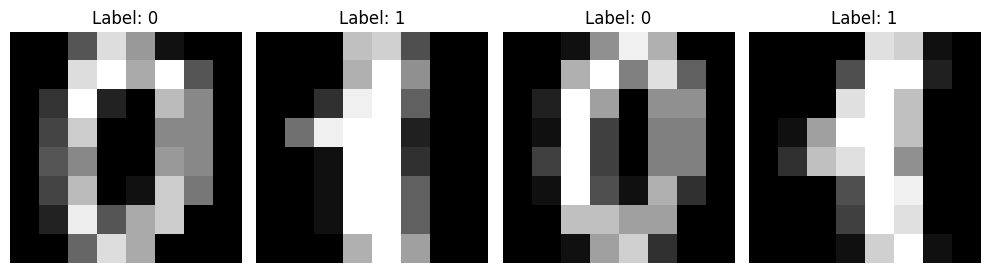

In [9]:


# Plot a few examples of 0s and 1s
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for i, ax in enumerate(axes):
    ax.imshow(X_raw[i], cmap='gray')
    ax.set_title(f"Label: {Y_raw[i]}")
    ax.axis('off')
    
plt.tight_layout()
plt.show()


---

## 3. Building the Core Components

We will build our algorithm in modular steps: Activation, Initialization, Propagation, and Optimization.

### Step 3.1: The Sigmoid Function




Why do we need the Sigmoid function? If we just use the linear step $z = w^T x + b$, our output could be any number from negative infinity to positive infinity. But we need a probability between 0 and 1 to classify an image as a '0' or a '1'.The Sigmoid function, mathematically defined as $\sigma(z) = \frac{1}{1 + e^{-z}}$, gracefully 'squashes' our linear output. Let's plot it to see this in action.

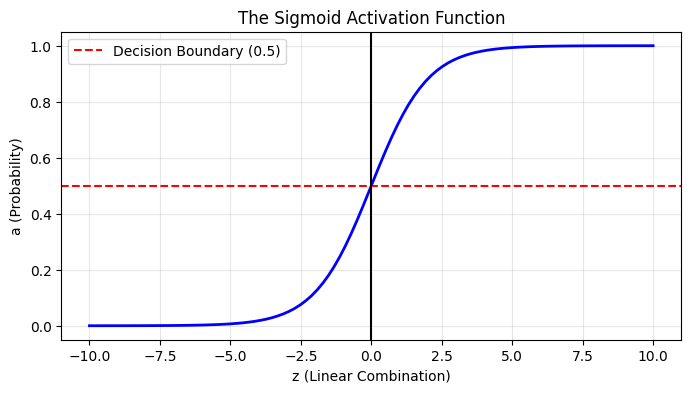

In [10]:
# Generate a range of numbers from -10 to 10
z_vals = np.linspace(-10, 10, 100)
# Pass them through our sigmoid function
a_vals = sigmoid(z_vals)

plt.figure(figsize=(8, 4))
plt.plot(z_vals, a_vals, color='blue', linewidth=2)
plt.title("The Sigmoid Activation Function")
plt.xlabel("z (Linear Combination)")
plt.ylabel("a (Probability)")
plt.axhline(y=0.5, color='r', linestyle='--', label="Decision Boundary (0.5)")
plt.axvline(x=0, color='k', linestyle='-')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

This function allows our linear equation to output a probability.

In [2]:

def sigmoid(z):
    """
    Computes the sigmoid of z.
    """
    return 1 / (1 + np.exp(-z))




### Step 3.2: Parameter Initialization
We need to initialize our weights vector $w$ to zeros (or small random numbers) and our bias $b$ to zero. Note that $w$ must have the same number of dimensions as our flattened image (64 in this case).



In [3]:
def initialize_params(dim):
    """
    Creates a vector of zeros of shape (dim, 1) for w and initializes b to 0.
    """
    w = np.zeros((dim, 1))
    b = 0.0
    return w, b

### Step 3.3: Forward and Backward Propagation



You might wonder why we don't just use Mean Squared Error (MSE) like we do in linear regression. If we use MSE with the non-linear Sigmoid function, the resulting cost function becomes non-convex—meaning it has multiple local minimums where our gradient descent could get stuck.Instead, we use Log-Loss. Let's look at the math for a single example where the true label is $y=1$. The loss simplifies to $-\log(a)$. As our predicted probability $a$ approaches 1, the penalty drops to 0. But if our model predicts 0 (completely wrong), the penalty shoots up to infinity. Let's visualize this exact penalty mechanism.

<>:10: SyntaxWarning: invalid escape sequence '\l'
<>:11: SyntaxWarning: invalid escape sequence '\l'
<>:10: SyntaxWarning: invalid escape sequence '\l'
<>:11: SyntaxWarning: invalid escape sequence '\l'
/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_43804/1142108631.py:10: SyntaxWarning: invalid escape sequence '\l'
  plt.plot(a, cost_y1, label="Cost if y=1: $-\log(a)$", color='green', linewidth=2)
/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_43804/1142108631.py:11: SyntaxWarning: invalid escape sequence '\l'
  plt.plot(a, cost_y0, label="Cost if y=0: $-\log(1-a)$", color='red', linewidth=2)


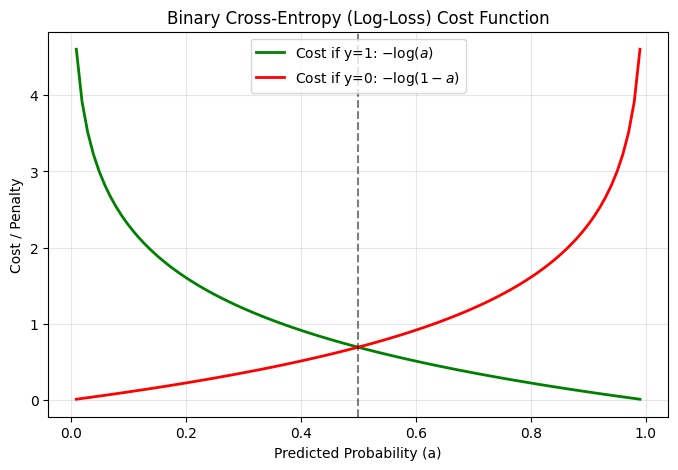

In [11]:
# Probabilities from 0.01 to 0.99 (avoiding 0 and 1 to prevent log(0) errors)
a = np.linspace(0.01, 0.99, 100)

# Cost when the true label (y) is 1
cost_y1 = -np.log(a)
# Cost when the true label (y) is 0
cost_y0 = -np.log(1 - a)

plt.figure(figsize=(8, 5))
plt.plot(a, cost_y1, label="Cost if y=1: $-\log(a)$", color='green', linewidth=2)
plt.plot(a, cost_y0, label="Cost if y=0: $-\log(1-a)$", color='red', linewidth=2)

plt.title("Binary Cross-Entropy (Log-Loss) Cost Function")
plt.xlabel("Predicted Probability (a)")
plt.ylabel("Cost / Penalty")
plt.axvline(x=0.5, color='k', linestyle='--', alpha=0.5)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

This is the engine of our neural network. Notice how we avoid `for` loops entirely. By relying on NumPy's vectorized operations (`np.dot`), we compute the cost and gradients for the entire dataset simultaneously. This is critical for computational efficiency in deep learning.

In [4]:
def propagate(w, b, X, Y):
    """
    Computes the cost function and its gradients.
    """
    m = X.shape[1] # Number of training examples
    
    # 1. FORWARD PROPAGATION
    A = sigmoid(np.dot(w.T, X) + b)
    
    # Compute the cross-entropy cost
    cost = (-1 / m) * np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A))
    
    # 2. BACKWARD PROPAGATION
    dw = (1 / m) * np.dot(X, (A - Y).T)
    db = (1 / m) * np.sum(A - Y)
    
    cost = np.squeeze(cost) # Ensure cost is a scalar
    grads = {"dw": dw, "db": db}
    
    return grads, cost

### Step 3.4: Optimization (Gradient Descent)
Now we update our parameters iteratively to minimize the cost.

In [5]:
def optimize(w, b, X, Y, num_iterations=1000, learning_rate=0.01, print_cost=False):
    """
    Optimizes w and b by running gradient descent.
    """
    costs = []
    
    for i in range(num_iterations):
        # Calculate gradients and cost
        grads, cost = propagate(w, b, X, Y)
        
        dw = grads["dw"]
        db = grads["db"]
        
        # Update rule
        w = w - learning_rate * dw
        b = b - learning_rate * db
        
        # Record the cost every 100 iterations
        if i % 100 == 0:
            costs.append(cost)
            if print_cost:
                print(f"Cost after iteration {i}: {cost:.4f}")
                
    params = {"w": w, "b": b}
    return params, costs

### Step 3.5: Prediction
Once the model is trained, we compute the activations for new data. If the probability is greater than 0.5, we classify it as a `1`, otherwise `0`.

In [6]:
def predict(w, b, X):
    """
    Predict whether the label is 0 or 1.
    """
    m = X.shape[1]
    Y_prediction = np.zeros((1, m))
    
    # Compute vector A predicting probabilities
    A = sigmoid(np.dot(w.T, X) + b)
    
    # Convert probabilities to binary predictions
    for i in range(A.shape[1]):
        Y_prediction[0, i] = 1 if A[0, i] > 0.5 else 0
        
    return Y_prediction


## 4. Assembling the Final Model

Let's wrap all our modular functions into a single pipeline.


In [7]:
def build_and_train_model(X_train, Y_train, X_test, Y_test, num_iterations=2000, learning_rate=0.5):
    # Initialize parameters based on feature count
    dim = X_train.shape[0]
    w, b = initialize_params(dim)
    
    # Gradient descent
    params, costs = optimize(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost=True)
    
    w = params["w"]
    b = params["b"]
    
    # Evaluate performance
    Y_prediction_train = predict(w, b, X_train)
    Y_prediction_test = predict(w, b, X_test)
    
    print(f"\nTrain accuracy: {100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100:.2f}%")
    print(f"Test accuracy: {100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100:.2f}%")
    
    return costs

### Running the Model

Cost after iteration 0: 0.6931
Cost after iteration 100: 0.1444
Cost after iteration 200: 0.0832
Cost after iteration 300: 0.0600
Cost after iteration 400: 0.0476
Cost after iteration 500: 0.0398
Cost after iteration 600: 0.0344
Cost after iteration 700: 0.0304
Cost after iteration 800: 0.0274
Cost after iteration 900: 0.0249

Train accuracy: 100.00%
Test accuracy: 100.00%


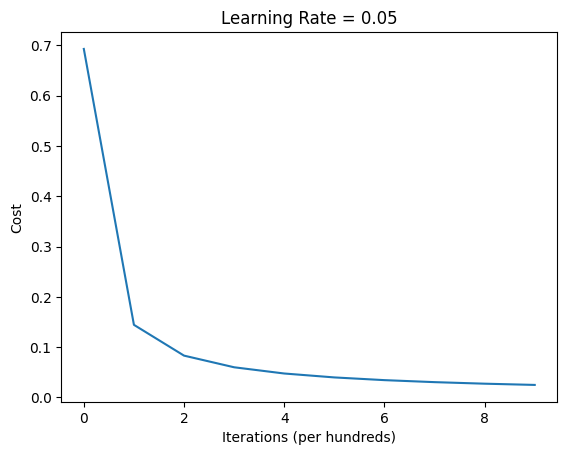

In [8]:
# Train the model!
costs = build_and_train_model(X_train, Y_train, X_test, Y_test, num_iterations=1000, learning_rate=0.05)

# Plot the learning curve
plt.plot(costs)
plt.ylabel('Cost')
plt.xlabel('Iterations (per hundreds)')
plt.title("Learning Rate = 0.05")
plt.show()



## Takeaways

By writing this from scratch, you have just implemented the fundamental building blocks of Deep Learning:
1.  **Vectorization**: Using `np.dot` avoids nested loops, shifting the heavy computational lifting to highly optimized linear algebra libraries. 
2.  **Forward Propagation**: Transforming data via matrix multiplication and non-linear activation functions.
3.  **Backpropagation**: Utilizing calculus and the chain rule to figure out exactly how much each weight contributed to the final error.

While a single layer restricts us to finding *linear* boundaries between data, stacking these exact same equations into hidden layers creates Deep Neural Networks capable of recognizing faces, driving cars, and generating text.